## Install and Import Libraries

In [1]:
#pip install nsepy

In [2]:
#%pip install nsepy pandas numpy matplotlib seaborn statsmodels scikit-learn

In [3]:
#%pip install yfinance

In [4]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

## Download and Check Stock Data

In [5]:
stk_data = yf.download("TATACONSUM.NS", start = "2022-06-01", end = "2023-01-05")

[*********************100%***********************]  1 of 1 completed


In [6]:
stk_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 150 entries, 2022-06-01 to 2023-01-04
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   (Close, TATACONSUM.NS)   150 non-null    float64
 1   (High, TATACONSUM.NS)    150 non-null    float64
 2   (Low, TATACONSUM.NS)     150 non-null    float64
 3   (Open, TATACONSUM.NS)    150 non-null    float64
 4   (Volume, TATACONSUM.NS)  150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 7.0 KB


In [7]:
stk_data

Price,Close,High,Low,Open,Volume
Ticker,TATACONSUM.NS,TATACONSUM.NS,TATACONSUM.NS,TATACONSUM.NS,TATACONSUM.NS
Date,,,,,
2022-06-01,730.223511,748.836511,727.009438,729.168159,1641729
2022-06-02,727.489136,729.647857,716.695528,726.289846,630109
2022-06-03,723.315613,739.721872,721.540629,729.168123,1747685
2022-06-06,732.670044,738.762412,715.064437,726.049942,1441390
2022-06-07,725.906006,731.086960,715.831973,731.086960,1346609
...,...,...,...,...,...
2022-12-29,750.538452,753.342962,737.966618,753.342962,1691955
2022-12-30,741.689880,756.534292,739.804093,752.375928,715796


## Prepare Column Names

In [8]:
# Check whether the column names have multiple levels. Ex:("Close", "TATACONSUM.NS")
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)  # Keep only the first level: Close, High, Low, Open, Volume.

In [9]:
# Copy the stock data, including the simplified column names.
dataset = stk_data.copy()

In [10]:
dataset

Price,Close,High,Low,Open,Volume
Date,,,,,
2022-06-01,730.223511,748.836511,727.009438,729.168159,1641729
2022-06-02,727.489136,729.647857,716.695528,726.289846,630109
2022-06-03,723.315613,739.721872,721.540629,729.168123,1747685
2022-06-06,732.670044,738.762412,715.064437,726.049942,1441390
2022-06-07,725.906006,731.086960,715.831973,731.086960,1346609
...,...,...,...,...,...
2022-12-29,750.538452,753.342962,737.966618,753.342962,1691955
2022-12-30,741.689880,756.534292,739.804093,752.375928,715796
2023-01-02,737.192993,745.606463,733.131312,744.542716,1061086


## Calculate Descriptive Statistics

In [11]:
from Descriptive import Descriptive

In [12]:
# Create an object using the corrected class.
obj = Descriptive()

In [13]:
# Identify numeric and categorical columns.
quan, qual = obj.segreQuanQual(dataset)

The Quantitative Data: ['Close', 'High', 'Low', 'Open', 'Volume']
The Qualtitative Data []


In [14]:
# Calculate descriptive.
des_data = obj.descriptive_Analysis(dataset, quan)

In [15]:
display(des_data)

,Close,High,Low,Open,Volume
Null_count,0,0,0,0,0
NonNull_count,150,150,150,150,150
Total_Count,150,150,150,150,150
Mean,754.533997,762.638261,746.799091,755.169709,1612684.76
Median,754.793579,766.712657,747.613112,755.27711,1268384.5
Mode,744.784546,695.996123,674.043728,676.94492,292558
Std,28.705692,28.57031,28.64458,28.757864,1446941.752347
Min,683.085754,695.996123,674.043728,676.94492,292558.0
Q1:25%,737.253418,745.703178,732.551114,739.804096,958242.0
Q2:50%,754.793579,766.712657,747.613112,755.27711,1268384.5


In [16]:
des_data["Low"]

Null_count                0
NonNull_count           150
Total_Count             150
Mean             746.799091
Median           747.613112
Mode             674.043728
Std                28.64458
Min              674.043728
Q1:25%           732.551114
Q2:50%           747.613112
Q3:75%           768.465454
Q4:100%          810.931602
IQR                35.91434
1.5Rule            53.87151
Lesser           678.679604
Greater          822.336964
Name: Low, dtype: object

In [17]:
des_data["High"]

Null_count                0
NonNull_count           150
Total_Count             150
Mean             762.638261
Median           766.712657
Mode             695.996123
Std                28.57031
Min              695.996123
Q1:25%           745.703178
Q2:50%           766.712657
Q3:75%           783.309889
Q4:100%          832.787286
IQR               37.606711
1.5Rule           56.410067
Lesser           689.293111
Greater          839.719956
Name: High, dtype: object

## Calculate Percentiles

In [18]:
import numpy as np

In [19]:
np.percentile(dataset["Low"], 99)

np.float64(803.1032887873807)

In [20]:
np.percentile(dataset["High"], 80)

np.float64(785.8169667793951)

## Explore the Price Distribution

In [21]:
def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color='Red')
    pyplot.axvline(endrange,color='Red')
    # generate a sample
    sample = dataset
    # calculate parameters
    sample_mean =sample.mean()
    sample_std = sample.std()
    print('Mean=%.3f, Standard Deviation=%.3f' % (sample_mean, sample_std))
    # define the distribution
    dist = norm(sample_mean, sample_std)
    
    # sample probabilities for a range of outcomes
    values = [value for value in range(startrange, endrange)]
    probabilities = [dist.pdf(value) for value in values]    
    prob=sum(probabilities)
    print("The area between range({},{}):{}".format(startrange,endrange,sum(probabilities)))
    return prob

Mean=746.799, Standard Deviation=28.645
The area between range(219,230):3.279592760972516e-73


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_10903/132380739.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')


np.float64(3.279592760972516e-73)

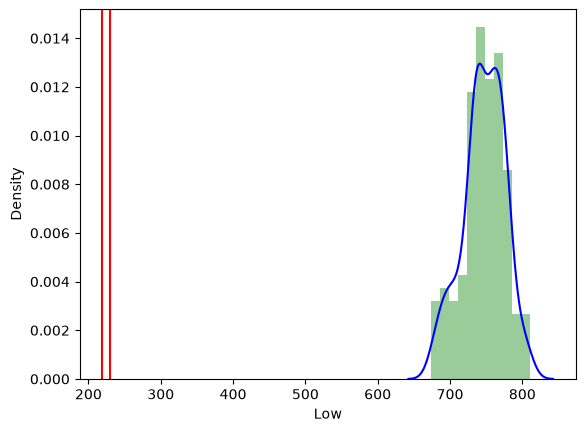

In [22]:
get_pdf_probability(dataset["Low"], 219, 230)

## Standardize Prices

In [23]:
def stdNBgraph(dataset):
        # Coverted to standard Normal Distribution
    import seaborn as sns
    mean=dataset.mean()
    std=dataset.std()

    values=[i for i in dataset]

    z_score=[((j-mean)/std) for j in values]

    sns.distplot(z_score,kde=True)

    sum(z_score)/len(z_score)
    #z_score.std()

/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_10903/4109782476.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(z_score,kde=True)


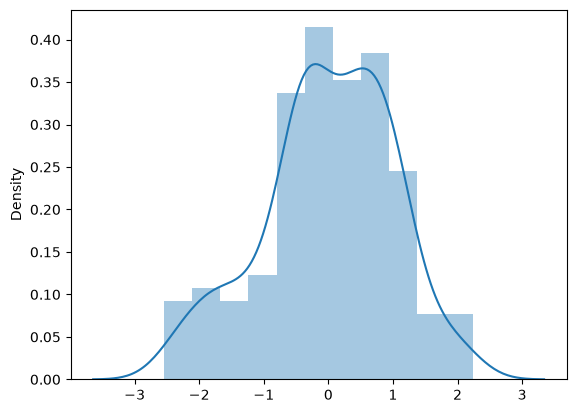

In [24]:
stdNBgraph(dataset["Low"])

## Create Frequency Tables

In [25]:
def freqTable(columnName,dataset):
    import pandas as pd
    frq = pd.DataFrame()
    frq["Unique_Values"] = dataset[columnName].value_counts().index
    frq["Frequency"] = dataset[columnName].value_counts().values
    frq["Relative_Fre"] = dataset[columnName].value_counts().values/len(dataset[columnName])*100
    frq["Cumulative"] = frq["Relative_Fre"].cumsum()
    return frq

In [26]:
freqTable("Low", dataset)

,Unique_Values,Frequency,Relative_Fre,Cumulative
0,727.009438,1,0.666667,0.666667
1,716.695528,1,0.666667,1.333333
2,721.540629,1,0.666667,2.000000
3,715.064437,1,0.666667,2.666667
4,715.831973,1,0.666667,3.333333
...,...,...,...,...
145,737.966618,1,0.666667,97.333333
146,739.804093,1,0.666667,98.000000
147,733.131312,1,0.666667,98.666667
148,734.098387,1,0.666667,99.333333


In [27]:
freqTable("High", dataset)

,Unique_Values,Frequency,Relative_Fre,Cumulative
0,748.836511,1,0.666667,0.666667
1,729.647857,1,0.666667,1.333333
2,739.721872,1,0.666667,2.000000
3,738.762412,1,0.666667,2.666667
4,731.086960,1,0.666667,3.333333
...,...,...,...,...
145,753.342962,1,0.666667,97.333333
146,756.534292,1,0.666667,98.000000
147,745.606463,1,0.666667,98.666667
148,742.608599,1,0.666667,99.333333


# Find Repeated High Prices

In [28]:
# Save the High-price frequency table.
fh = freqTable("High", dataset)

In [29]:
# Display the most frequent prices first; this does not change fh.
fh.sort_values(by="Frequency", ascending=False)

,Unique_Values,Frequency,Relative_Fre,Cumulative
0,748.836511,1,0.666667,0.666667
94,746.525229,1,0.666667,63.333333
96,751.408857,1,0.666667,64.666667
97,746.573578,1,0.666667,65.333333
98,755.132038,1,0.666667,66.000000
...,...,...,...,...
50,772.249055,1,0.666667,34.000000
51,750.345199,1,0.666667,34.666667
52,754.890285,1,0.666667,35.333333
53,770.314951,1,0.666667,36.000000


In [30]:
# Select prices that appear at least twice.
fhs = fh.loc[fh["Frequency"] == 2, "Unique_Values"].sort_values(ascending=False)

display(fhs)

Series([], Name: Unique_Values, dtype: float64)